<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%2011/Praktikum%202%20(JS11).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Ilustrasi Data Non-Linier

##Langkah 1a - Import Library

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

##Langkah 1b - Buat Kembali Fungsi Plotting

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

##Langkah 1c - Buat Data Dummy Non-Linier

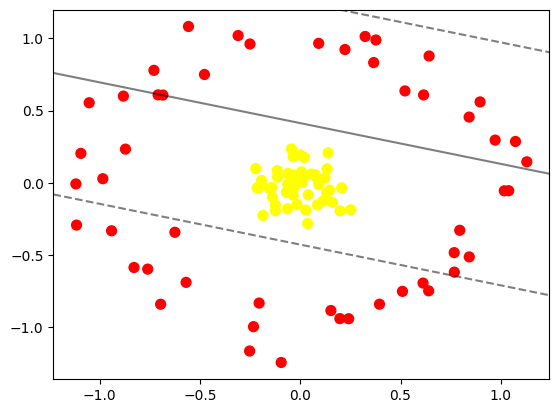

In [3]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [4]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 51.0 MB/s eta 0:00:00


In [7]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Definisikan kembali variabel r (proyeksi radial)
r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 6.40355078e-01, -7.46510709e-01],
       [-6.84815624e-01,  6.07797196e-01],
       [-1.09347650e+00,  2.04358821e-01],
       [-8.81603913e-01,  6.00367894e-01],
       [-7.60278322e-01, -5.96302354e-01],
       [-2.33014971e-01, -9.94383149e-01],
       [ 5.55874332e-02,  6.10847874e-02],
       [ 7.42477804e-02,  5.72897262e-02],
       [-7.08426988e-01,  6.09006843e-01],
       [ 1.60395817e-01, -1.34261408e-01],
       [-3.09636819e-01,  1.01925790e+00],
       [-6.26751523e-02, -8.21467266e-03],
       [ 7.67651492e-01, -4.82249250e-01],
       [-1.61284454e-02, -1.49477483e-01],
       [-2.09038880e-01, -3.38371369e-02],
       [ 6.14991315e-01,  6.08446096e-01],
       [ 1.38559689e-01,  2.08081075e-01],
       [ 2.41669878e-01, -9.39446993e-01],
       [-2.50557552e-01,  9.60820751e-01],
       [-2.22105886e-01,  9.97427718e-02],
       [ 1.52838909e-01, -8.82855759e-01],
       [ 8.42070057e-01,  4.55536795e-01],
       [ 5.92963875e-03,  7.68904434e-02],
       [-1.11833303e+00, -6.94095468e-03],
       [ 3.72250496e-02, -2.80425067e-01],
       [ 1.34308535e-01,  9.75055653e-02],
       [-5.69049838e-01, -6.87817444e-01],
       [ 7.95264565e-01, -3.27730440e-01],
       [ 8.62939515e-02, -1.52451385e-01],
       [-1.41465729e-01, -3.20373222e-02],
       [ 2.76232921e-02, -1.87527568e-01],
       [-2.60365421e-02, -2.27941779e-02],
       [ 1.45603395e-01, -4.96195501e-02],
       [ 1.23859034e-01,  3.49615869e-02],
       [-1.11518552e+00, -2.91678230e-01],
       [ 5.09638204e-01, -7.50070738e-01],
       [ 9.71684802e-01,  2.96056873e-01],
       [-5.61211714e-02,  5.98285431e-02],
       [-1.23500276e-01, -1.92567261e-01],
       [ 1.06192581e-02,  3.61495946e-03],
       [-6.95848111e-01, -8.39123469e-01],
       [-3.50186518e-02,  1.80845399e-01],
       [ 1.98537322e-01, -1.93086960e-01],
       [-2.42280822e-03,  1.13517873e-02],
       [-1.05213144e+00,  5.54443270e-01],
       [ 1.97624376e-01, -9.38596584e-01],
       [-1.13303388e-01,  4.05026955e-02],
       [-2.04927666e-01, -8.31093630e-01],
       [ 3.77314404e-01,  9.88717020e-01],
       [ 2.94301219e-03,  3.71307659e-02],
       [ 7.68219488e-01, -6.17022175e-01],
       [ 2.23182350e-01,  9.22588778e-01],
       [ 3.95017811e-01, -8.38926604e-01],
       [-2.14342824e-01, -3.38007606e-02],
       [-5.57096749e-01,  1.08202838e+00],
       [ 1.03942781e+00, -5.40867241e-02],
       [-1.54874139e-01, -3.74241621e-02],
       [-3.50939190e-02, -8.43013215e-02],
       [-6.91245276e-02, -6.41801937e-02],
       [ 1.01731607e+00, -5.46012665e-02],
       [ 6.12297289e-01, -6.92801753e-01],
       [ 5.22158414e-01,  6.36211298e-01],
       [ 3.66178649e-01,  8.32218085e-01],
       [ 2.00742365e-02,  1.76700024e-01],
       [-1.38514644e-01, -9.79118397e-02],
       [ 1.14497133e-01, -1.25063691e-01],
       [ 1.07301627e+00,  2.86566135e-01],
       [ 3.23590950e-01,  1.01295560e+00],
       [-6.24750077e-01, -3.41334201e-01],
       [-1.24169103e-01, -1.52961663e-01],
       [-8.28582771e-01, -5.85002824e-01],
       [ 4.00082147e-02, -8.22154361e-02],
       [-3.15166238e-02,  5.44380610e-02],
       [ 6.42554297e-01,  8.77690897e-01],
       [-1.14868548e-01,  8.53135746e-02],
       [-9.84053677e-01,  2.89815005e-02],
       [-1.92620257e-01,  1.67931952e-02],
       [-9.40518672e-01, -3.31155859e-01],
       [ 7.72452895e-02,  4.13843550e-02],
       [-4.77359278e-01,  7.49869152e-01],
       [-2.52304725e-01, -1.16276418e+00],
       [-9.48522706e-02, -1.24202980e+00],
       [-8.71186969e-01,  2.33684854e-01],
       [ 1.32040900e-01, -7.07377739e-02],
       [ 8.96626140e-01,  5.60173278e-01],
       [ 2.52520900e-01, -1.85527401e-01],
       [ 2.24345543e-02,  4.71934303e-02],
       [ 8.42589685e-01, -5.11858069e-01],
       [ 1.21332655e-04,  1.93715303e-01],
       [ 9.21543562e-02,  9.65361911e-01],
       [-6.36470562e-02, -1.79204034e-01],
       [ 1.12953015e+00,  1.45969158e-01

#Langkah 2 - Fitting Model

In [8]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

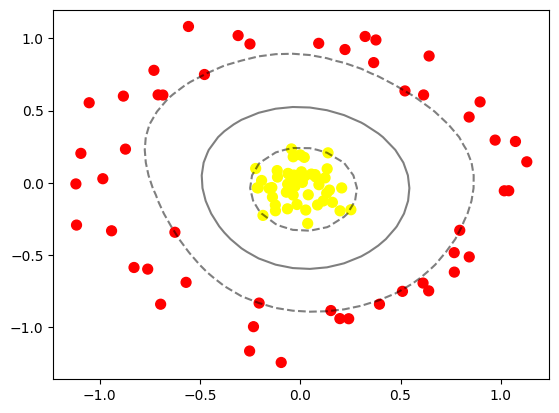

In [11]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')